# Ejercicio 2. Agrupamiento por densidad mediante DBSCAN

En este ejercicio se generará un conjunto de 500 observaciones con forma de dos medias lunas, utilizando `make_moons` de Scikit-learn.

Se aplicará **DBSCAN**, un algoritmo que forma grupos según la densidad de los datos y permite identificar puntos como ruido. Se probarán diferentes combinaciones de `eps` y `min_samples` para analizar cómo influyen en los agrupamientos.

Finalmente, se seleccionará una configuración, se visualizarán los clústeres y se evaluarán los resultados, considerando el tratamiento de los puntos clasificados como ruido.

Número de registros: 500
Número de variables: 2


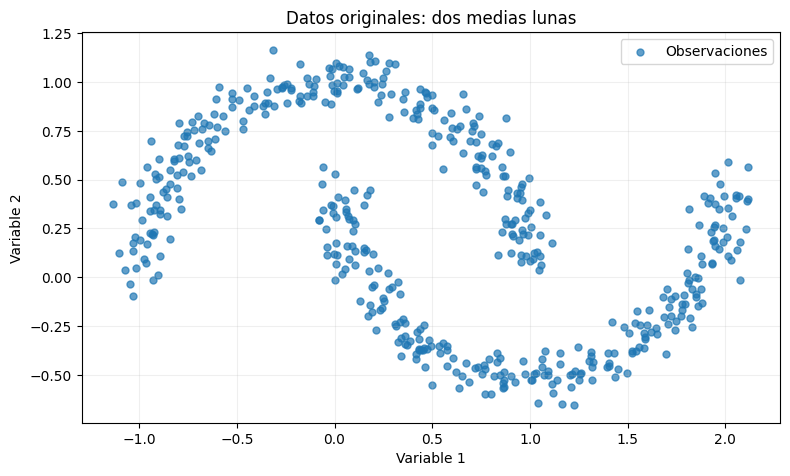

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# Generar los datos con los parámetros solicitados.
# Descartar las etiquetas originales.
datos, _ = make_moons(
    n_samples=500,
    noise=0.07,
    random_state=42
)

X_moons = pd.DataFrame(datos, columns=["Variable 1", "Variable 2"])

print("Número de registros:", X_moons.shape[0])
print("Número de variables:", X_moons.shape[1])

# Visualizar las observaciones antes del agrupamiento.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    X_moons["Variable 1"],
    X_moons["Variable 2"],
    s=25,
    alpha=0.7,
    label="Observaciones"
)

ax.set_title("Datos originales: dos medias lunas")
ax.set_xlabel("Variable 1")
ax.set_ylabel("Variable 2")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 2. Estandarización de los datos

Se aplica **StandardScaler** para que ambas variables tengan media cercana a cero y desviación estándar de uno.

DBSCAN utiliza distancias para identificar observaciones vecinas, por lo que la escala de las variables influye en el agrupamiento. Después de esta transformación, el parámetro `eps` se interpretará en el espacio estandarizado.

Se conservan los datos originales en `X_moons` y se almacenan los datos transformados en `X_moons_scaled`.


In [2]:
from sklearn.preprocessing import StandardScaler

# Ajustar el escalador y transformar las dos variables.
scaler_moons = StandardScaler()
X_moons_scaled = scaler_moons.fit_transform(X_moons)

# Conservar los nombres de las columnas y el índice.
X_moons_scaled = pd.DataFrame(
    X_moons_scaled,
    columns=X_moons.columns,
    index=X_moons.index
)

# Comprobar el resultado de la estandarización.
verificacion_moons = pd.DataFrame({
    "Media": X_moons_scaled.mean(),
    "Desviación estándar": X_moons_scaled.std(ddof=0)
})

display(verificacion_moons.round(4))

,Media,Desviación estándar
Variable 1,-0.0,1.0
Variable 2,-0.0,1.0


## 3. Evaluación de configuraciones de DBSCAN

Se prueban diferentes combinaciones de dos parámetros:

- **`eps`:** distancia máxima para considerar que dos observaciones son vecinas.
- **`min_samples`:** número mínimo de observaciones en el vecindario de un punto, incluido el propio punto, para considerarlo un punto núcleo.

Para cada configuración se registra el número de clústeres y la cantidad y porcentaje de observaciones clasificadas como ruido. DBSCAN identifica

In [3]:
from sklearn.cluster import DBSCAN

configuraciones = [
    (0.10, 5),
    (0.20, 5),
    (0.30, 5),
    (0.20, 10),
    (0.60, 5)
]

resultados_dbscan = []
etiquetas_por_config = {}

for eps, min_samples in configuraciones:
    modelo = DBSCAN(eps=eps, min_samples=min_samples)
    etiquetas = modelo.fit_predict(X_moons_scaled)

    # Guardar las etiquetas para visualizar los resultados después.
    etiquetas_por_config[(eps, min_samples)] = etiquetas

    # Excluir la etiqueta de ruido al contar los grupos.
    n_clusters = len(set(etiquetas) - {-1})
    n_ruido = int((etiquetas == -1).sum())

    resultados_dbscan.append({
        "eps": eps,
        "min_samples": min_samples,
        "Clústeres": n_clusters,
        "Puntos de ruido": n_ruido,
        "Ruido (%)": 100 * n_ruido / len(etiquetas)
    })

tabla_dbscan = pd.DataFrame(resultados_dbscan)
display(tabla_dbscan.round(2))

,eps,min_samples,Clústeres,Puntos de ruido,Ruido (%)
0,0.1,5,24,118,23.6
1,0.2,5,2,4,0.8
2,0.3,5,2,0,0.0
3,0.2,10,2,8,1.6
4,0.6,5,1,0,0.0


## 4. Comparación visual de las configuraciones

Se representan los agrupamientos obtenidos con cada configuración de DBSCAN. Los colores distinguen los clústeres dentro de cada gráfica y las cruces negras indican las observaciones clasificadas como ruido.

La comparación permitirá identificar qué configuraciones conservan las dos estructuras curvas sin fragmentarlas en numerosos grupos ni unirlas en uno solo. La elección no dependerá únicamente de reducir el porcentaje de ruido.

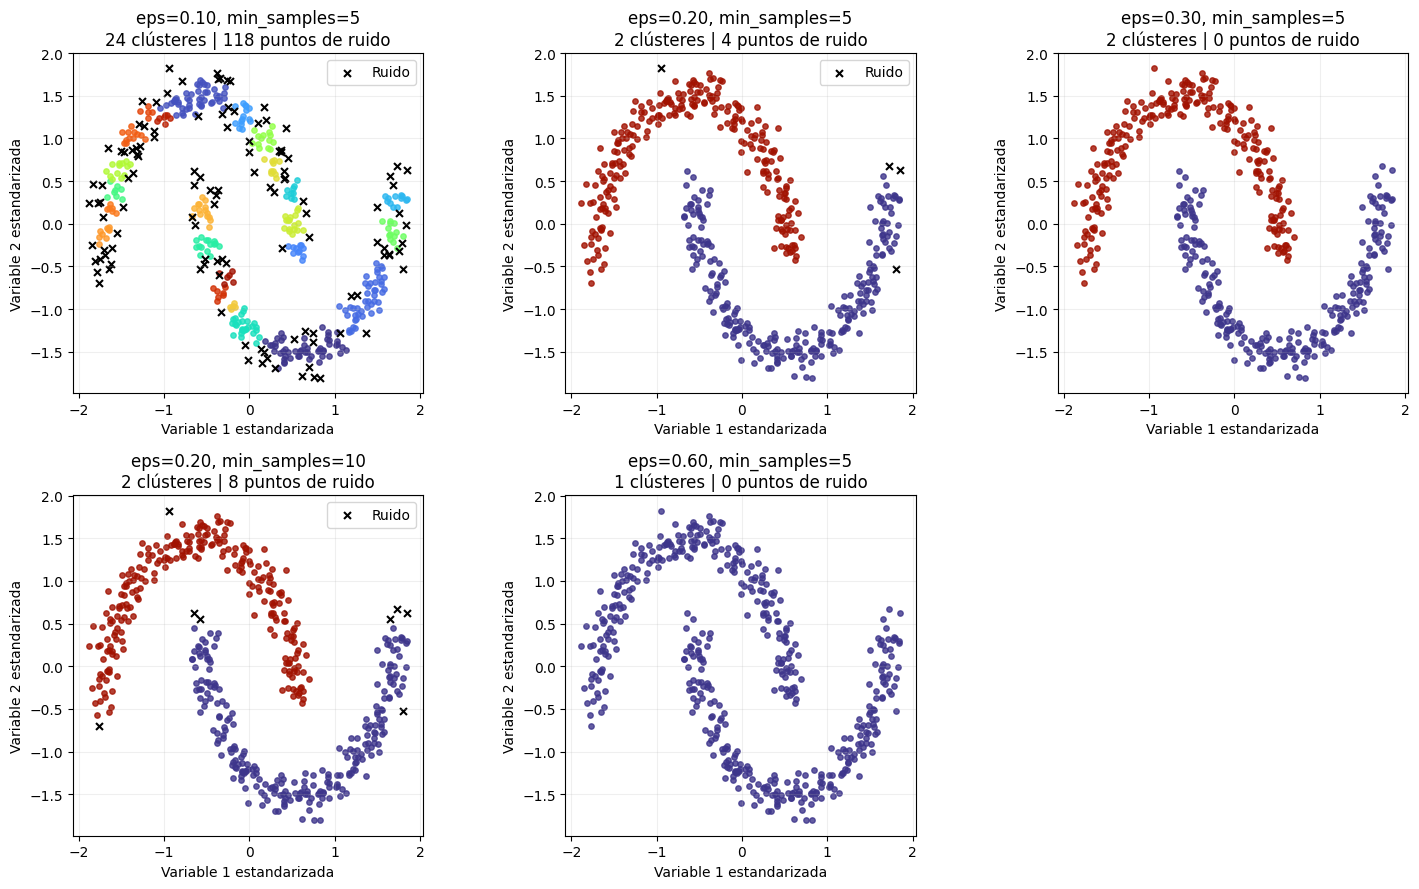

In [4]:
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (eps, min_samples) in zip(axes.flat, configuraciones):
    etiquetas = etiquetas_por_config[(eps, min_samples)]
    grupos = sorted(set(etiquetas) - {-1})
    colores = plt.cm.turbo(np.linspace(0.05, 0.95, len(grupos)))

    # Dibujar cada clúster con un color diferente.
    for grupo, color in zip(grupos, colores):
        seleccion = etiquetas == grupo
        ax.scatter(
            X_moons_scaled.loc[seleccion, "Variable 1"],
            X_moons_scaled.loc[seleccion, "Variable 2"],
            color=color,
            s=15,
            alpha=0.8
        )

    # Representar el ruido por separado.
    ruido = etiquetas == -1
    if ruido.any():
        ax.scatter(
            X_moons_scaled.loc[ruido, "Variable 1"],
            X_moons_scaled.loc[ruido, "Variable 2"],
            color="black",
            marker="x",
            s=25,
            label="Ruido"
        )
        ax.legend()

    ax.set_title(
        f"eps={eps:.2f}, min_samples={min_samples}\n"
        f"{len(grupos)} clústeres | {ruido.sum()} puntos de ruido"
    )
    ax.set_xlabel("Variable 1 estandarizada")
    ax.set_ylabel("Variable 2 estandarizada")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

# Ocultar el panel que no se utiliza.
axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

## 5. Selección de la configuración y evaluación final

Se selecciona **eps = 0,30 y min_samples = 5**, porque identifica dos clústeres que siguen las estructuras curvas observadas, sin fragmentarlas ni fusionarlas. Esta configuración no clasifica observaciones como ruido.

Con eps = 0,10, el vecindario resulta demasiado pequeño y se obtienen 24 grupos y un 23,6 % de ruido. En cambio, con eps = 0,60 se conectan ambas estructuras y se forma un único clúster. Al mantener eps = 0,20 y aumentar min_samples de 5 a 10, el porcentaje de ruido pasa del 0,8 % al 1,6 %, porque se exige una mayor densidad para formar puntos núcleo.

Se calculan Silhouette, Davies-Bouldin y Calinski-Harabasz excluyendo las observaciones con etiqueta −1. El ruido no se considera un clúster adicional. En la configuración seleccionada no hay ruido, por lo que las métricas utilizan

In [5]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Entrenar DBSCAN con la configuración seleccionada.
dbscan_final = DBSCAN(eps=0.30, min_samples=5)
clusters_dbscan = dbscan_final.fit_predict(X_moons_scaled)

# Excluir el ruido para evaluar únicamente los clústeres.
sin_ruido = clusters_dbscan != -1
X_validos = X_moons_scaled.loc[sin_ruido]
etiquetas_validas = clusters_dbscan[sin_ruido]

n_clusters = len(set(etiquetas_validas))
n_ruido = int((~sin_ruido).sum())

# Las métricas requieren entre 2 y n_muestras - 1 grupos.
if 2 <= n_clusters < len(X_validos):
    metricas_dbscan = pd.DataFrame([{
        "eps": 0.30,
        "min_samples": 5,
        "Clústeres": n_clusters,
        "Puntos de ruido": n_ruido,
        "Silhouette": silhouette_score(X_validos, etiquetas_validas),
        "Davies-Bouldin": davies_bouldin_score(
            X_validos, etiquetas_validas
        ),
        "Calinski-Harabasz": calinski_harabasz_score(
            X_validos, etiquetas_validas
        )
    }])

    display(metricas_dbscan.round(4))
else:
    print("La configuración no permite calcular estas métricas.")

,eps,min_samples,Clústeres,Puntos de ruido,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,0.3,5,2,0,0.3857,1.0215,433.8817


## 6. Interpretación de los resultados y conclusiones

La configuración seleccionada de DBSCAN, con **eps = 0,30 y min_samples = 5**, identificó dos clústeres que siguen la forma de las medias lunas. Las 500 observaciones fueron asignadas a un grupo, sin puntos clasificados como ruido.

Se obtuvieron los siguientes indicadores:

- **Silhouette: 0,3857.** Indica una separación positiva, aunque limitada según este criterio.
- **Davies-Bouldin: 1,0215.**
- **Calinski-Harabasz: 433,8817.**

Los dos últimos indicadores sirven para comparar configuraciones sobre los mismos datos y no tienen un umbral universal que permita calificarlos por sí solos. Además, estas métricas deben complementarse con la visualización, porque los grupos tienen formas curvas y no son necesariamente compactos alrededor de un centro.

### Efecto de los parámetros y tratamiento del ruido

Un valor demasiado pequeño de `eps` fragmentó las estructuras en numerosos grupos y aumentó el ruido. Un valor demasiado grande conectó ambas medias lunas y produjo un único clúster.

El parámetro `min_samples` establece la cantidad mínima de observaciones en un vecindario, incluido el propio punto, para considerarlo núcleo. Aumentarlo exige mayor densidad y puede incrementar el número de observaciones clasificadas como ruido.

Los puntos con etiqueta **−1** son observaciones que el algoritmo no incorpora a ningún clúster bajo los parámetros elegidos. Esto no significa necesariamente que sean errores. Para evaluar los grupos, se excluyen del cálculo de las métricas y se informa su proporción. En el modelo seleccionado no fue necesario excluir observaciones.

### Ventajas y limitaciones

DBSCAN puede seguir estructuras curvas mediante conexiones entre regiones densas. Por ello, puede reconocer formas que resultan difíciles para K-Means, cuyo criterio favorece grupos compactos alrededor de centroides.

Sus principales ventajas son detectar ruido y formar grupos sin definir previamente su cantidad. Sus limitaciones incluyen la sensibilidad a la escala y a los parámetros, así como la dificultad para identificar grupos con densidades muy diferentes.

### Conclusión

DBSCAN permitió recuperar las dos estructuras curvas con la configuración seleccionada. La comparación de parámetros mostró que una elección inadecuada puede fragmentar los grupos o fusionarlos. La selección se justificó combinando la forma observada, el número de clústeres y el porcentaje de ruido, con las métricas como evidencia complementaria.